<a href="https://colab.research.google.com/github/VijayReddy-07/Fruit-Classification-Quality-Grading/blob/main/FCQG_using_DenseNet121.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# CELL 1: Mount Google Drive
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted successfully!")

Mounted at /content/drive
Google Drive mounted successfully!


In [2]:
# ============================================================
# CELL 2: Import Required Libraries
# ============================================================

import os
import time
import copy
import shutil
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.transforms import v2
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    densenet121,
    DenseNet121_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tqdm.auto import tqdm

print("Libraries imported successfully!")

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Libraries imported successfully!
Device: cuda
GPU: Tesla T4


In [3]:
# ============================================================
# CELL 3: DenseNet121 Project Paths
# ============================================================

PROJECT_PATH = "/content/drive/MyDrive/Fruit_Classification_project"

SPLIT_PATH = os.path.join(PROJECT_PATH, "splits")

TRAIN_CSV = os.path.join(SPLIT_PATH, "train.csv")
VAL_CSV   = os.path.join(SPLIT_PATH, "val.csv")
TEST_CSV  = os.path.join(SPLIT_PATH, "test.csv")

# DenseNet121 checkpoint directories
DENSENET121_FRUIT_CHECKPOINT_DIR = os.path.join(
    PROJECT_PATH, "DenseNet121_Fruit_Checkpoints"
)

DENSENET121_QUALITY_CHECKPOINT_DIR = os.path.join(
    PROJECT_PATH, "DenseNet121_Quality_Checkpoints"
)

# Create directories
os.makedirs(DENSENET121_FRUIT_CHECKPOINT_DIR, exist_ok=True)
os.makedirs(DENSENET121_QUALITY_CHECKPOINT_DIR, exist_ok=True)

# Check files
print("Project Path:")
print(PROJECT_PATH)

print("\nCSV Files:")
print("Train CSV:", os.path.exists(TRAIN_CSV))
print("Validation CSV:", os.path.exists(VAL_CSV))
print("Test CSV:", os.path.exists(TEST_CSV))

print("\nCheckpoint Directories:")
print("Fruit:",
      DENSENET121_FRUIT_CHECKPOINT_DIR)

print("Quality:",
      DENSENET121_QUALITY_CHECKPOINT_DIR)

Project Path:
/content/drive/MyDrive/Fruit_Classification_project

CSV Files:
Train CSV: True
Validation CSV: True
Test CSV: True

Checkpoint Directories:
Fruit: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints
Quality: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints


In [4]:
# ============================================================
# CELL 4: Load Train, Validation, and Test CSV Files
# ============================================================

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print("Dataset loaded successfully!\n")

print("Train samples      :", len(train_df))
print("Validation samples :", len(val_df))
print("Test samples       :", len(test_df))
print("Total samples      :", len(train_df) + len(val_df) + len(test_df))

print("\nCSV Columns:")
print(train_df.columns.tolist())

print("\nTrain Dataset Preview:")
display(train_df.head())

print("\nFruit Classes:")
print(sorted(train_df["fruit"].unique()))

print("\nQuality Classes:")
print(sorted(train_df["quality"].unique()))

Dataset loaded successfully!

Train samples      : 13668
Validation samples : 3906
Test samples       : 1953
Total samples      : 19527

CSV Columns:
['image_path', 'fruit', 'quality', 'combined_label']

Train Dataset Preview:


,image_path,fruit,quality,combined_label
0,/content/drive/MyDrive/Fruit_Classification_Pr...,Pomegranate,Good,Pomegranate_Good
1,/content/drive/MyDrive/Fruit_Classification_Pr...,Banana,Bad,Banana_Bad
2,/content/drive/MyDrive/Fruit_Classification_Pr...,Pomegranate,Good,Pomegranate_Good
3,/content/drive/MyDrive/Fruit_Classification_Pr...,Apple,Good,Apple_Good
4,/content/drive/MyDrive/Fruit_Classification_Pr...,Guava,Good,Guava_Good



Fruit Classes:
['Apple', 'Banana', 'Guava', 'Lime', 'Orange', 'Pomegranate']

Quality Classes:
['Bad', 'Good', 'Mixed']


In [5]:
# ============================================================
# CELL 5: Define Image Transforms
# ============================================================

# Training transformation
transform = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomRotation(degrees=45),
    v2.GaussianBlur(kernel_size=3),
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing transformation
preprocess = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# AugMix for training
balance = v2.Compose([
    v2.AugMix(
        severity=3,
        mixture_width=3,
        chain_depth=-1,
        alpha=1.
    )
])

print("Training transform:")
print(transform)

print("\nValidation/Test transform:")
print(preprocess)

print("\nAugMix transform:")
print(balance)

Training transform:
Compose(
      Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
      RandomHorizontalFlip(p=0.5)
      RandomVerticalFlip(p=0.5)
      RandomRotation(degrees=[-45.0, 45.0], interpolation=InterpolationMode.NEAREST, expand=False, fill=0)
      GaussianBlur(kernel_size=(3, 3), sigma=[0.1, 2.0])
      ToImage()
      ToDtype(scale=True)
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
)

Validation/Test transform:
Compose(
      Resize(size=[224, 224], interpolation=InterpolationMode.BILINEAR, antialias=True)
      ToImage()
      ToDtype(scale=True)
      ToDtype(scale=True)
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], inplace=False)
)

AugMix transform:
Compose(    AugMix(interpolation=InterpolationMode.BILINEAR, severity=3, mixture_width=3, chain_depth=-1, alpha=1.0, all_ops=True))


In [6]:
# ============================================================
# CELL 6: Define Fruit and Quality Class Mappings
# ============================================================

# Fruit class mapping
fruit_types = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

fruit_to_idx = {
    fruit: idx
    for idx, fruit in enumerate(fruit_types)
}

idx_to_fruit = {
    idx: fruit
    for fruit, idx in fruit_to_idx.items()
}


# Quality class mapping
quality_types = [
    "Good",
    "Bad",
    "Mixed"
]

quality_to_idx = {
    quality: idx
    for idx, quality in enumerate(quality_types)
}

idx_to_quality = {
    idx: quality
    for quality, idx in quality_to_idx.items()
}


# Number of classes
num_fruit_classes = len(fruit_types)
num_quality_classes = len(quality_types)


# Display mappings
print("Fruit Classes:")
print(fruit_to_idx)

print("\nQuality Classes:")
print(quality_to_idx)

print("\nNumber of Fruit Classes:", num_fruit_classes)
print("Number of Quality Classes:", num_quality_classes)

Fruit Classes:
{'Apple': 0, 'Banana': 1, 'Guava': 2, 'Lime': 3, 'Orange': 4, 'Pomegranate': 5}

Quality Classes:
{'Good': 0, 'Bad': 1, 'Mixed': 2}

Number of Fruit Classes: 6
Number of Quality Classes: 3


In [7]:
# ============================================================
# CELL 7: Create Fruit and Quality Dataset Classes
# ============================================================

class FruitDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Image path
        image_path = row["image_path"]

        # Open image
        from PIL import Image
        image = Image.open(image_path).convert("RGB")

        # Apply transformation
        if self.transform:
            image = self.transform(image)

        # Fruit label
        fruit_label = fruit_to_idx[row["fruit"]]

        return image, fruit_label


class QualityDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Image path
        image_path = row["image_path"]

        # Open image
        from PIL import Image
        image = Image.open(image_path).convert("RGB")

        # Apply transformation
        if self.transform:
            image = self.transform(image)

        # Quality label
        quality_label = quality_to_idx[row["quality"]]

        return image, quality_label


print("FruitDataset class created successfully!")
print("QualityDataset class created successfully!")

FruitDataset class created successfully!
QualityDataset class created successfully!


In [8]:
# ============================================================
# CELL 8: Create Train, Validation, and Test Datasets
# ============================================================

# -------------------------
# Fruit Classification
# -------------------------

f_train_dataset = FruitDataset(
    train_df,
    transform=transform
)

f_val_dataset = FruitDataset(
    val_df,
    transform=preprocess
)

f_test_dataset = FruitDataset(
    test_df,
    transform=preprocess
)


# -------------------------
# Quality Classification
# -------------------------

q_train_dataset = QualityDataset(
    train_df,
    transform=transform
)

q_val_dataset = QualityDataset(
    val_df,
    transform=preprocess
)

q_test_dataset = QualityDataset(
    test_df,
    transform=preprocess
)


# -------------------------
# Display Dataset Sizes
# -------------------------

print("Fruit Classification Datasets")
print("--------------------------------")
print("Training   :", len(f_train_dataset))
print("Validation :", len(f_val_dataset))
print("Testing    :", len(f_test_dataset))

print("\nQuality Classification Datasets")
print("--------------------------------")
print("Training   :", len(q_train_dataset))
print("Validation :", len(q_val_dataset))
print("Testing    :", len(q_test_dataset))

Fruit Classification Datasets
--------------------------------
Training   : 13668
Validation : 3906
Testing    : 1953

Quality Classification Datasets
--------------------------------
Training   : 13668
Validation : 3906
Testing    : 1953


In [9]:
# ============================================================
# CELL 9: Create DataLoaders
# ============================================================

BATCH_SIZE = 8
NUM_WORKERS = 2

# -------------------------
# Fruit Classification
# -------------------------

f_train_loader = DataLoader(
    f_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

f_val_loader = DataLoader(
    f_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

f_test_loader = DataLoader(
    f_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# -------------------------
# Quality Classification
# -------------------------

q_train_loader = DataLoader(
    q_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

q_val_loader = DataLoader(
    q_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

q_test_loader = DataLoader(
    q_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# -------------------------
# Verify
# -------------------------

print("DataLoaders created successfully!")

print("\nBatch Size:", BATCH_SIZE)
print("Number of Workers:", NUM_WORKERS)

print("\nFruit Classification:")
print("Training batches   :", len(f_train_loader))
print("Validation batches :", len(f_val_loader))
print("Testing batches    :", len(f_test_loader))

print("\nQuality Classification:")
print("Training batches   :", len(q_train_loader))
print("Validation batches :", len(q_val_loader))
print("Testing batches    :", len(q_test_loader))

DataLoaders created successfully!

Batch Size: 8
Number of Workers: 2

Fruit Classification:
Training batches   : 1709
Validation batches : 489
Testing batches    : 245

Quality Classification:
Training batches   : 1709
Validation batches : 489
Testing batches    : 245


In [10]:
# ============================================================
# CELL 10: DenseNet121 Model for Fruit Classification
# ============================================================

# Load pretrained DenseNet121
model = densenet121(
    weights=DenseNet121_Weights.IMAGENET1K_V1
)

# Get the number of input features of the classifier
num_features = model.classifier.in_features

# Replace ImageNet classifier with 6 fruit classes
model.classifier = nn.Linear(
    num_features,
    num_fruit_classes
)

# Move model to GPU/CPU
model = model.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
# Learning rate is FIXED at 0.01
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-2
)

# Number of training epochs
NUM_EPOCHS = 30

# Display model information
print("DenseNet121 model created successfully!")

print("\nModel:")
print(model)

print("\nNumber of Fruit Classes:", num_fruit_classes)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", 0.01)
print("Epochs:", NUM_EPOCHS)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 155MB/s]


DenseNet121 model created successfully!

Model:
DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affi

In [11]:
# ============================================================
# CELL 10A: Rebuild and Verify Image Paths
# ============================================================

import os

# Actual dataset folder
DATASET_PATH = os.path.join(
    PROJECT_PATH,
    "FruitNetDataset"
)

print("Dataset path:")
print(DATASET_PATH)

print("\nDataset exists:", os.path.exists(DATASET_PATH))

Dataset path:
/content/drive/MyDrive/Fruit_Classification_project/FruitNetDataset

Dataset exists: True


In [12]:
# ============================================================
# CELL 10A: Quickly Fix Image Paths
# ============================================================

OLD_PATH = "/content/drive/MyDrive/Fruit_Classification_Project"

NEW_PATH = "/content/drive/MyDrive/Fruit_Classification_project"

# Fix paths
train_df["image_path"] = train_df["image_path"].str.replace(
    OLD_PATH,
    NEW_PATH,
    regex=False
)

val_df["image_path"] = val_df["image_path"].str.replace(
    OLD_PATH,
    NEW_PATH,
    regex=False
)

test_df["image_path"] = test_df["image_path"].str.replace(
    OLD_PATH,
    NEW_PATH,
    regex=False
)

# Check paths
train_missing = (~train_df["image_path"].apply(os.path.exists)).sum()
val_missing = (~val_df["image_path"].apply(os.path.exists)).sum()
test_missing = (~test_df["image_path"].apply(os.path.exists)).sum()

print("Train missing images      :", train_missing)
print("Validation missing images :", val_missing)
print("Test missing images       :", test_missing)

print("\nExample corrected path:")
print(train_df["image_path"].iloc[0])

Train missing images      : 0
Validation missing images : 0
Test missing images       : 0

Example corrected path:
/content/drive/MyDrive/Fruit_Classification_project/FruitNetDataset/Good Quality_Fruits/Pomegranate_Good/20190820_151028_24470.jpg


In [13]:
# ============================================================
# CELL 10B: Recreate Datasets and DataLoaders
# ============================================================

BATCH_SIZE = 8
NUM_WORKERS = 2


# ------------------------------------------------------------
# Create Fruit Datasets
# ------------------------------------------------------------

f_train_dataset = FruitDataset(
    train_df,
    transform=transform
)

f_val_dataset = FruitDataset(
    val_df,
    transform=preprocess
)

f_test_dataset = FruitDataset(
    test_df,
    transform=preprocess
)


# ------------------------------------------------------------
# Create Quality Datasets
# ------------------------------------------------------------

q_train_dataset = QualityDataset(
    train_df,
    transform=transform
)

q_val_dataset = QualityDataset(
    val_df,
    transform=preprocess
)

q_test_dataset = QualityDataset(
    test_df,
    transform=preprocess
)


# ------------------------------------------------------------
# Fruit DataLoaders
# ------------------------------------------------------------

f_train_loader = DataLoader(
    f_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

f_val_loader = DataLoader(
    f_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

f_test_loader = DataLoader(
    f_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# ------------------------------------------------------------
# Quality DataLoaders
# ------------------------------------------------------------

q_train_loader = DataLoader(
    q_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

q_val_loader = DataLoader(
    q_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

q_test_loader = DataLoader(
    q_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("DataLoaders recreated successfully!")

print("\nBatch Size:", BATCH_SIZE)
print("Number of Workers:", NUM_WORKERS)

print("\nFruit Classification:")
print("Training batches   :", len(f_train_loader))
print("Validation batches :", len(f_val_loader))
print("Testing batches    :", len(f_test_loader))

print("\nQuality Classification:")
print("Training batches   :", len(q_train_loader))
print("Validation batches :", len(q_val_loader))
print("Testing batches    :", len(q_test_loader))

DataLoaders recreated successfully!

Batch Size: 8
Number of Workers: 2

Fruit Classification:
Training batches   : 1709
Validation batches : 489
Testing batches    : 245

Quality Classification:
Training batches   : 1709
Validation batches : 489
Testing batches    : 245


In [14]:
# ============================================================
# CELL 11: DenseNet121 Fruit Classification Training
# ============================================================

# Checkpoint paths
checkpoint_dir = DENSENET121_FRUIT_CHECKPOINT_DIR

latest_checkpoint = os.path.join(
    checkpoint_dir,
    "latest_checkpoint.pth"
)

best_model_path = os.path.join(
    checkpoint_dir,
    "best_model.pth"
)

# Training history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Best validation accuracy
best_val_accuracy = 0.0

# Starting epoch
start_epoch = 0


# ============================================================
# Automatic Checkpoint Loading
# ============================================================

if os.path.exists(latest_checkpoint):

    print("Checkpoint found!")
    print("Loading:", latest_checkpoint)

    checkpoint = torch.load(
        latest_checkpoint,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1
    best_val_accuracy = checkpoint["best_val_accuracy"]

    train_losses = checkpoint.get(
        "train_losses",
        []
    )

    val_losses = checkpoint.get(
        "val_losses",
        []
    )

    train_accuracies = checkpoint.get(
        "train_accuracies",
        []
    )

    val_accuracies = checkpoint.get(
        "val_accuracies",
        []
    )

    print(
        f"Resuming training from epoch "
        f"{start_epoch + 1}/{NUM_EPOCHS}"
    )

else:

    print("No previous checkpoint found.")
    print("Starting training from Epoch 1.")


# ============================================================
# Training Loop
# ============================================================

for epoch in range(start_epoch, NUM_EPOCHS):

    print(
        f"\n{'=' * 70}"
    )

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"{'=' * 70}"
    )


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_progress = tqdm(
        f_train_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} - Training",
        unit="batch"
    )

    for batch_idx, (images, labels) in enumerate(
        train_progress
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total += labels.size(0)

        # Progress percentage
        progress_percent = (
            (batch_idx + 1)
            / len(f_train_loader)
            * 100
        )

        train_progress.set_postfix(
            loss=f"{loss.item():.4f}",
            progress=f"{progress_percent:.1f}%"
        )


    epoch_train_loss = (
        running_loss / total
    )

    epoch_train_accuracy = (
        correct / total
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    val_progress = tqdm(
        f_val_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} - Validation",
        unit="batch"
    )

    with torch.no_grad():

        for batch_idx, (images, labels) in enumerate(
            val_progress
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(
                outputs,
                labels
            )

            # Statistics
            val_running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            val_total += labels.size(0)

            # Progress percentage
            progress_percent = (
                (batch_idx + 1)
                / len(f_val_loader)
                * 100
            )

            val_progress.set_postfix(
                loss=f"{loss.item():.4f}",
                progress=f"{progress_percent:.1f}%"
            )


    epoch_val_loss = (
        val_running_loss / val_total
    )

    epoch_val_accuracy = (
        val_correct / val_total
    )


    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------

    train_losses.append(
        epoch_train_loss
    )

    val_losses.append(
        epoch_val_loss
    )

    train_accuracies.append(
        epoch_train_accuracy
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    # --------------------------------------------------------
    # Print Epoch Results
    # --------------------------------------------------------

    print(
        f"\nEpoch {epoch + 1} Training Loss: "
        f"{epoch_train_loss:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Training Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Validation Loss: "
        f"{epoch_val_loss:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )

    print(
        "Current Learning Rate: 0.01"
    )


    # --------------------------------------------------------
    # Save Latest Checkpoint
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracies": train_accuracies,
        "val_accuracies": val_accuracies
    }

    torch.save(
        checkpoint,
        latest_checkpoint
    )

    print(
        "Latest checkpoint saved:"
    )

    print(
        latest_checkpoint
    )


    # --------------------------------------------------------
    # Save Best Model
    # --------------------------------------------------------

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = epoch_val_accuracy

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"Best model saved!"
        )

        print(
            f"Best Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )


print(
    "\n" + "=" * 70
)

print(
    "DenseNet121 Fruit Classification Training Completed"
)

print(
    "=" * 70
)

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Best Model Path: "
    f"{best_model_path}"
)

Checkpoint found!
Loading: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints/latest_checkpoint.pth
Resuming training from epoch 31/30

DenseNet121 Fruit Classification Training Completed
Best Validation Accuracy: 0.9516
Best Model Path: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints/best_model.pth


In [15]:
# ============================================================
# CHECK DENSENET121 CHECKPOINT FILES
# ============================================================

checkpoint_dir = DENSENET121_FRUIT_CHECKPOINT_DIR

print("Checkpoint directory:")
print(checkpoint_dir)

print("\nFiles available:")

if os.path.exists(checkpoint_dir):

    files = os.listdir(checkpoint_dir)

    for file in files:
        print(" -", file)

else:
    print("Checkpoint directory does NOT exist!")

Checkpoint directory:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints

Files available:
 - best_model.pth
 - latest_checkpoint.pth


In [16]:
# ============================================================
# CELL 12: DenseNet121 Fruit Classification Testing
# ============================================================

best_model_path = os.path.join(
    DENSENET121_FRUIT_CHECKPOINT_DIR,
    "best_model.pth"
)

print("Loading best DenseNet121 model...")
print("Path:", best_model_path)


# ------------------------------------------------------------
# Create DenseNet121 Model
# ------------------------------------------------------------

model = densenet121(
    weights=None
)

num_features = model.classifier.in_features

model.classifier = nn.Linear(
    num_features,
    num_fruit_classes
)


# ------------------------------------------------------------
# Load Best Model
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("\nBest DenseNet121 model loaded successfully!")


# ------------------------------------------------------------
# Testing
# ------------------------------------------------------------

all_predictions = []
all_labels = []

total_inference_time = 0.0
total_samples = 0

print("\nStarting DenseNet121 Fruit Classification Testing...")

with torch.no_grad():

    test_bar = tqdm(
        f_test_loader,
        desc="DenseNet121 Testing",
        unit="batch"
    )

    for images, labels in test_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_time = time.time()

        outputs = model(images)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        inference_time = time.time() - start_time

        total_inference_time += inference_time
        total_samples += images.size(0)

        _, predictions = torch.max(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


# ------------------------------------------------------------
# Convert to NumPy
# ------------------------------------------------------------

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# Inference Time
# ------------------------------------------------------------

average_inference_time = (
    total_inference_time / total_samples
)


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

classification_report_result = classification_report(
    all_labels,
    all_predictions,
    target_names=fruit_types,
    zero_division=0
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

conf_matrix = confusion_matrix(
    all_labels,
    all_predictions
)


# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("DenseNet121 Fruit Classification Testing Results")
print("=" * 70)

print(f"\nNumber of Test Samples: {len(all_labels)}")

print(
    f"\nFruit Test Accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Fruit Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"\nWeighted Precision: "
    f"{test_precision:.4f}"
)

print(
    f"Weighted Precision: "
    f"{test_precision * 100:.2f}%"
)

print(
    f"\nWeighted Recall: "
    f"{test_recall:.4f}"
)

print(
    f"Weighted Recall: "
    f"{test_recall * 100:.2f}%"
)

print(
    f"\nWeighted F1-score: "
    f"{test_f1:.4f}"
)

print(
    f"Weighted F1-score: "
    f"{test_f1 * 100:.2f}%"
)

print(
    f"\nAverage Inference Time: "
    f"{average_inference_time:.6f} seconds/sample"
)


# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("Fruit Classification Report")
print("=" * 70)

print(classification_report_result)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

print("=" * 70)
print("Fruit Confusion Matrix")
print("=" * 70)

print(conf_matrix)

print("\nDenseNet121 testing completed successfully!")

Loading best DenseNet121 model...
Path: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints/best_model.pth

Best DenseNet121 model loaded successfully!

Starting DenseNet121 Fruit Classification Testing...


DenseNet121 Testing:   0%|          | 0/245 [00:00<?, ?batch/s]



DenseNet121 Fruit Classification Testing Results

Number of Test Samples: 1953

Fruit Test Accuracy: 0.9488
Fruit Test Accuracy: 94.88%

Weighted Precision: 0.9490
Weighted Precision: 94.90%

Weighted Recall: 0.9488
Weighted Recall: 94.88%

Weighted F1-score: 0.9485
Weighted F1-score: 94.85%

Average Inference Time: 0.007416 seconds/sample

Fruit Classification Report
              precision    recall  f1-score   support

       Apple       0.91      0.90      0.91       240
      Banana       0.94      0.99      0.96       249
       Guava       0.94      0.90      0.92       243
        Lime       0.92      0.87      0.90       245
      Orange       0.91      0.97      0.94       251
 Pomegranate       0.99      0.99      0.99       725

    accuracy                           0.95      1953
   macro avg       0.94      0.94      0.94      1953
weighted avg       0.95      0.95      0.95      1953

Fruit Confusion Matrix
[[215   4   4   3   9   5]
 [  1 247   0   0   0   1]
 [  9  

In [17]:
# ============================================================
# CELL 13: DenseNet121 Quality Classification Model Setup
# ============================================================

# ------------------------------------------------------------
# Quality checkpoint directory
# ------------------------------------------------------------

quality_checkpoint_dir = DENSENET121_QUALITY_CHECKPOINT_DIR

os.makedirs(
    quality_checkpoint_dir,
    exist_ok=True
)

print("Quality checkpoint directory:")
print(quality_checkpoint_dir)


# ------------------------------------------------------------
# Load Best DenseNet121 Fruit Model
# ------------------------------------------------------------

fruit_model_path = os.path.join(
    DENSENET121_FRUIT_CHECKPOINT_DIR,
    "best_model.pth"
)

print("\nLoading best DenseNet121 fruit model...")
print("Path:", fruit_model_path)


model = densenet121(
    weights=None
)

num_features = model.classifier.in_features

# First create the 6-class fruit classifier
model.classifier = nn.Linear(
    num_features,
    num_fruit_classes
)


# Load trained fruit-classification weights
fruit_state_dict = torch.load(
    fruit_model_path,
    map_location=device
)

model.load_state_dict(
    fruit_state_dict
)

print("Fruit model loaded successfully!")


# ------------------------------------------------------------
# Change Classifier: Fruit → Quality
# ------------------------------------------------------------

num_features = model.classifier.in_features

model.classifier = nn.Linear(
    num_features,
    num_quality_classes
)

model = model.to(device)


# ------------------------------------------------------------
# Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-2
)


# ------------------------------------------------------------
# Training Settings
# ------------------------------------------------------------

NUM_EPOCHS = 30
LEARNING_RATE = 0.01


# ------------------------------------------------------------
# Display Configuration
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DenseNet121 Quality Classification Setup")
print("=" * 60)

print("Model              : DenseNet121")
print("Fruit classes      :", num_fruit_classes)
print("Quality classes    :", num_quality_classes)
print("Quality labels     :", quality_types)
print("Batch size         :", BATCH_SIZE)
print("Learning rate      :", LEARNING_RATE)
print("Epochs             :", NUM_EPOCHS)
print("Scheduler          : None")
print("Device             :", device)

print("\nQuality model is ready for training!")

Quality checkpoint directory:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints

Loading best DenseNet121 fruit model...
Path: /content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Fruit_Checkpoints/best_model.pth
Fruit model loaded successfully!

DenseNet121 Quality Classification Setup
Model              : DenseNet121
Fruit classes      : 6
Quality classes    : 3
Quality labels     : ['Good', 'Bad', 'Mixed']
Batch size         : 8
Learning rate      : 0.01
Epochs             : 30
Scheduler          : None
Device             : cuda

Quality model is ready for training!


In [18]:
# ============================================================
# CELL 14: DenseNet121 Quality Classification Training
# ============================================================

import os
import torch
import torch.nn as nn
from torchvision.models import densenet121
from tqdm.auto import tqdm


# ============================================================
# CONFIGURATION
# ============================================================

NUM_CLASSES = 3
NUM_EPOCHS = 30
LEARNING_RATE = 0.01
BATCH_SIZE = 8


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# CHECKPOINT DIRECTORIES
# ============================================================

checkpoint_dir = DENSENET121_QUALITY_CHECKPOINT_DIR

os.makedirs(
    checkpoint_dir,
    exist_ok=True
)

latest_checkpoint = os.path.join(
    checkpoint_dir,
    "latest_checkpoint.pth"
)

best_model_path = os.path.join(
    checkpoint_dir,
    "best_model.pth"
)


print("\nCheckpoint Directory:")
print(checkpoint_dir)

print("\nLatest Checkpoint:")
print(latest_checkpoint)

print("\nBest Model:")
print(best_model_path)


# ============================================================
# CREATE DENSENET121 MODEL
# ============================================================

model = densenet121(
    weights="IMAGENET1K_V1"
)

# DenseNet121 final classifier input features
num_features = model.classifier.in_features

print("\nDenseNet121 Feature Size:")
print(num_features)


# ------------------------------------------------------------
# IMPORTANT:
# Quality classification has 3 classes:
#
# 0 = Good
# 1 = Bad
# 2 = Mixed
# ------------------------------------------------------------

model.classifier = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)


print("\n" + "=" * 70)
print("DenseNet121 Quality Classification Model")
print("=" * 70)

print("Number of Classes:", NUM_CLASSES)
print("Classes: Good, Bad, Mixed")
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)


# ============================================================
# LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-2
)


# ============================================================
# TRAINING HISTORY
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0

start_epoch = 0


# ============================================================
# AUTOMATIC CHECKPOINT RESUME
# ============================================================

if os.path.exists(latest_checkpoint):

    print("\n" + "=" * 70)
    print("Checkpoint found!")
    print("=" * 70)

    print("Loading:")
    print(latest_checkpoint)

    checkpoint = torch.load(
        latest_checkpoint,
        map_location=device
    )

    # --------------------------------------------------------
    # Load model weights
    # --------------------------------------------------------

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # --------------------------------------------------------
    # Load optimizer
    # --------------------------------------------------------

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # --------------------------------------------------------
    # Resume epoch
    # --------------------------------------------------------

    start_epoch = (
        checkpoint["epoch"] + 1
    )

    # --------------------------------------------------------
    # Load best validation accuracy
    # --------------------------------------------------------

    best_val_accuracy = checkpoint.get(
        "best_val_accuracy",
        0.0
    )

    # --------------------------------------------------------
    # Load training history
    # --------------------------------------------------------

    train_losses = checkpoint.get(
        "train_losses",
        []
    )

    val_losses = checkpoint.get(
        "val_losses",
        []
    )

    train_accuracies = checkpoint.get(
        "train_accuracies",
        []
    )

    val_accuracies = checkpoint.get(
        "val_accuracies",
        []
    )

    print(
        f"\nCheckpoint Epoch: "
        f"{checkpoint['epoch'] + 1}"
    )

    print(
        f"Resuming from Epoch: "
        f"{start_epoch + 1}/{NUM_EPOCHS}"
    )

    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.4f}"
    )

else:

    print("\n" + "=" * 70)
    print("No previous checkpoint found.")
    print("=" * 70)

    print(
        "Starting quality training from Epoch 1."
    )


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    start_epoch,
    NUM_EPOCHS
):

    print("\n" + "=" * 70)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    print("=" * 70)


    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    train_bar = tqdm(
        q_train_loader,
        desc=(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} "
            f"- Training"
        ),
        unit="batch"
    )


    for batch_idx, (
        images,
        labels
    ) in enumerate(train_bar):

        # ----------------------------------------------------
        # Move data to device
        # ----------------------------------------------------

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # ----------------------------------------------------
        # Clear gradients
        # ----------------------------------------------------

        optimizer.zero_grad()


        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        outputs = model(
            images
        )


        # ----------------------------------------------------
        # Calculate Loss
        # ----------------------------------------------------

        loss = criterion(
            outputs,
            labels
        )


        # ----------------------------------------------------
        # Backward Pass
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # Update Weights
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # Calculate Metrics
        # ----------------------------------------------------

        running_loss += (
            loss.item()
            * images.size(0)
        )


        _, predictions = torch.max(
            outputs,
            dim=1
        )


        total += labels.size(0)


        correct += (
            predictions == labels
        ).sum().item()


        # ----------------------------------------------------
        # Progress Percentage
        # ----------------------------------------------------

        progress = (
            (batch_idx + 1)
            / len(q_train_loader)
        ) * 100


        train_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            progress=f"{progress:.1f}%"
        )


    # ========================================================
    # EPOCH TRAINING METRICS
    # ========================================================

    epoch_train_loss = (
        running_loss / total
    )

    epoch_train_accuracy = (
        correct / total
    )


    train_losses.append(
        epoch_train_loss
    )

    train_accuracies.append(
        epoch_train_accuracy
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    validation_loss = 0.0

    val_correct = 0

    val_total = 0


    val_bar = tqdm(
        q_val_loader,
        desc=(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} "
            f"- Validation"
        ),
        unit="batch"
    )


    with torch.no_grad():

        for batch_idx, (
            images,
            labels
        ) in enumerate(val_bar):

            # ------------------------------------------------
            # Move data to device
            # ------------------------------------------------

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            # ------------------------------------------------
            # Forward Pass
            # ------------------------------------------------

            outputs = model(
                images
            )


            # ------------------------------------------------
            # Calculate Loss
            # ------------------------------------------------

            loss = criterion(
                outputs,
                labels
            )


            # ------------------------------------------------
            # Validation Metrics
            # ------------------------------------------------

            validation_loss += (
                loss.item()
                * images.size(0)
            )


            _, predictions = torch.max(
                outputs,
                dim=1
            )


            val_total += labels.size(0)


            val_correct += (
                predictions == labels
            ).sum().item()


            # ------------------------------------------------
            # Progress Percentage
            # ------------------------------------------------

            progress = (
                (batch_idx + 1)
                / len(q_val_loader)
            ) * 100


            val_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                progress=f"{progress:.1f}%"
            )


    # ========================================================
    # EPOCH VALIDATION METRICS
    # ========================================================

    epoch_val_loss = (
        validation_loss / val_total
    )

    epoch_val_accuracy = (
        val_correct / val_total
    )


    val_losses.append(
        epoch_val_loss
    )

    val_accuracies.append(
        epoch_val_accuracy
    )


    # ========================================================
    # PRINT EPOCH RESULTS
    # ========================================================

    print(
        f"\nEpoch {epoch + 1} Training Loss: "
        f"{epoch_train_loss:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Training Accuracy: "
        f"{epoch_train_accuracy:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Validation Loss: "
        f"{epoch_val_loss:.4f}"
    )

    print(
        f"Epoch {epoch + 1} Validation Accuracy: "
        f"{epoch_val_accuracy:.4f}"
    )

    print(
        f"Current Learning Rate: "
        f"{optimizer.param_groups[0]['lr']}"
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if (
        epoch_val_accuracy
        > best_val_accuracy
    ):

        best_val_accuracy = (
            epoch_val_accuracy
        )


        torch.save(
            model.state_dict(),
            best_model_path
        )


        print(
            f"Best model saved! "
            f"Validation Accuracy: "
            f"{best_val_accuracy:.4f}"
        )


    # ========================================================
    # SAVE LATEST CHECKPOINT
    # ========================================================

    checkpoint = {

        "epoch": epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "best_val_accuracy":
            best_val_accuracy,

        "train_losses":
            train_losses,

        "val_losses":
            val_losses,

        "train_accuracies":
            train_accuracies,

        "val_accuracies":
            val_accuracies
    }


    torch.save(
        checkpoint,
        latest_checkpoint
    )


    print(
        "\nLatest checkpoint saved:"
    )

    print(
        latest_checkpoint
    )


# ============================================================
# TRAINING COMPLETED
# ============================================================

print("\n" + "=" * 70)

print(
    "DenseNet121 Quality Classification "
    "Training Completed"
)

print("=" * 70)


print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Best Validation Accuracy: "
    f"{best_val_accuracy * 100:.2f}%"
)


print(
    "\nBest Model Path:"
)

print(
    best_model_path
)

Device: cuda

Checkpoint Directory:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints

Latest Checkpoint:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints/latest_checkpoint.pth

Best Model:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints/best_model.pth

DenseNet121 Feature Size:
1024

DenseNet121 Quality Classification Model
Number of Classes: 3
Classes: Good, Bad, Mixed
Batch Size: 8
Learning Rate: 0.01

Checkpoint found!
Loading:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints/latest_checkpoint.pth

Checkpoint Epoch: 30
Resuming from Epoch: 31/30
Best Validation Accuracy: 0.9552

DenseNet121 Quality Classification Training Completed
Best Validation Accuracy: 0.9552
Best Validation Accuracy: 95.52%

Best Model Path:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints/best_model.pth


In [19]:
# ============================================================
# CELL 15: DenseNet121 Quality Classification Testing
# ============================================================

import os
import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
from torchvision.models import densenet121
import torch.nn as nn


# ============================================================
# CONFIGURATION
# ============================================================

NUM_CLASSES = 3

quality_classes = [
    "Good",
    "Bad",
    "Mixed"
]


# ============================================================
# CREATE MODEL
# ============================================================

model = densenet121(
    weights=None
)

num_features = model.classifier.in_features

model.classifier = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)


# ============================================================
# LOAD BEST MODEL
# ============================================================

print("Loading best DenseNet121 quality model:")

print(best_model_path)

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model.eval()

print("\nBest model loaded successfully.")


# ============================================================
# TESTING
# ============================================================

all_predictions = []
all_labels = []

total_inference_time = 0.0
total_samples = 0


test_bar = tqdm(
    q_test_loader,
    desc="Testing DenseNet121 Quality",
    unit="batch"
)


with torch.no_grad():

    for images, labels in test_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        # ----------------------------------------------------
        # Synchronize GPU before timing
        # ----------------------------------------------------

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = torch.cuda.Event(
            enable_timing=True
        ) if device.type == "cuda" else None

        end_time = torch.cuda.Event(
            enable_timing=True
        ) if device.type == "cuda" else None


        if device.type == "cuda":

            start_time.record()

            outputs = model(images)

            end_time.record()

            torch.cuda.synchronize()

            batch_time = (
                start_time.elapsed_time(end_time)
                / 1000.0
            )

        else:

            import time

            cpu_start = time.perf_counter()

            outputs = model(images)

            cpu_end = time.perf_counter()

            batch_time = (
                cpu_end - cpu_start
            )


        # ----------------------------------------------------
        # Predictions
        # ----------------------------------------------------

        predictions = torch.argmax(
            outputs,
            dim=1
        )


        # ----------------------------------------------------
        # Store Results
        # ----------------------------------------------------

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )


        total_inference_time += batch_time

        total_samples += images.size(0)


# ============================================================
# CONVERT TO NUMPY
# ============================================================

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_predictions
)


precision, recall, f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=quality_classes,
    digits=4,
    zero_division=0
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)


# ============================================================
# INFERENCE TIME
# ============================================================

average_inference_time = (
    total_inference_time
    / total_samples
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)

print(
    "DenseNet121 Quality Classification "
    "Testing Results"
)

print("=" * 70)


print(
    f"\nNumber of Test Samples: "
    f"{total_samples}"
)


print(
    f"\nQuality Test Accuracy: "
    f"{accuracy:.4f}"
)


print(
    f"Quality Test Accuracy: "
    f"{accuracy * 100:.2f}%"
)


print(
    f"\nWeighted Precision: "
    f"{precision:.4f}"
)


print(
    f"Weighted Recall: "
    f"{recall:.4f}"
)


print(
    f"Weighted F1-score: "
    f"{f1:.4f}"
)


print(
    f"\nAverage Inference Time: "
    f"{average_inference_time:.6f} "
    f"seconds/sample"
)


print(
    "\nQuality Classification Report:"
)

print(report)


print(
    "Quality Confusion Matrix:"
)

print(cm)


print("\n" + "=" * 70)

print("FINAL DENSENET121 QUALITY RESULTS")

print("=" * 70)

print(
    f"Accuracy: "
    f"{accuracy * 100:.2f}%"
)

print(
    f"Weighted Precision: "
    f"{precision * 100:.2f}%"
)

print(
    f"Weighted Recall: "
    f"{recall * 100:.2f}%"
)

print(
    f"Weighted F1-score: "
    f"{f1 * 100:.2f}%"
)

print(
    f"Average Inference Time: "
    f"{average_inference_time:.6f} sec/sample"
)

Loading best DenseNet121 quality model:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Checkpoints/best_model.pth

Best model loaded successfully.


Testing DenseNet121 Quality:   0%|          | 0/245 [00:00<?, ?batch/s]


DenseNet121 Quality Classification Testing Results

Number of Test Samples: 1953

Quality Test Accuracy: 0.9421
Quality Test Accuracy: 94.21%

Weighted Precision: 0.9411
Weighted Recall: 0.9421
Weighted F1-score: 0.9410

Average Inference Time: 0.005786 seconds/sample

Quality Classification Report:
              precision    recall  f1-score   support

        Good     0.9548    0.9597    0.9572      1166
         Bad     0.9325    0.9558    0.9440       679
       Mixed     0.8471    0.6667    0.7461       108

    accuracy                         0.9421      1953
   macro avg     0.9114    0.8607    0.8824      1953
weighted avg     0.9411    0.9421    0.9410      1953

Quality Confusion Matrix:
[[1119   42    5]
 [  22  649    8]
 [  31    5   72]]

FINAL DENSENET121 QUALITY RESULTS
Accuracy: 94.21%
Weighted Precision: 94.11%
Weighted Recall: 94.21%
Weighted F1-score: 94.10%
Average Inference Time: 0.005786 sec/sample


<Figure size 700x600 with 0 Axes>

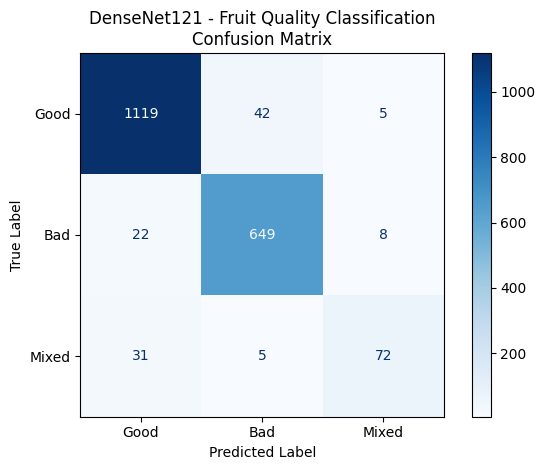

In [20]:
# ============================================================
# CELL 16: DenseNet121 Quality Confusion Matrix Visualization
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# ------------------------------------------------------------
# Calculate confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

# ------------------------------------------------------------
# Create confusion matrix image
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Good",
        "Bad",
        "Mixed"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    "DenseNet121 - Fruit Quality Classification\nConfusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.tight_layout()

plt.show()

In [21]:
# ============================================================
# CELL 17: Calculate Quality Class Weights
# ============================================================

import torch
import numpy as np
from collections import Counter


# ============================================================
# QUALITY CLASS MAPPING
# ============================================================

quality_to_idx = {
    "Good": 0,
    "Bad": 1,
    "Mixed": 2
}

idx_to_quality = {
    0: "Good",
    1: "Bad",
    2: "Mixed"
}


# ============================================================
# GET QUALITY LABELS FROM TRAINING DATA
# ============================================================

quality_labels = train_df["quality"].map(
    quality_to_idx
).values


# ============================================================
# COUNT SAMPLES IN EACH CLASS
# ============================================================

class_counts = Counter(
    quality_labels
)


print("=" * 60)
print("Quality Class Distribution")
print("=" * 60)

for class_idx in range(3):

    class_name = idx_to_quality[class_idx]

    count = class_counts[class_idx]

    print(
        f"{class_name}: {count} samples"
    )


# ============================================================
# CALCULATE CLASS WEIGHTS
# ============================================================

total_samples = len(
    quality_labels
)

num_classes = 3


class_weights = []

for class_idx in range(
    num_classes
):

    count = class_counts[class_idx]

    weight = (
        total_samples
        / (num_classes * count)
    )

    class_weights.append(
        weight
    )


# ============================================================
# CONVERT TO PYTORCH TENSOR
# ============================================================

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


# ============================================================
# DISPLAY WEIGHTS
# ============================================================

print("\n" + "=" * 60)
print("Quality Class Weights")
print("=" * 60)

for class_idx in range(3):

    print(
        f"{idx_to_quality[class_idx]}: "
        f"{class_weights[class_idx].item():.4f}"
    )


print("\nClass weights tensor:")
print(class_weights)

Quality Class Distribution
Good: 8164 samples
Bad: 4752 samples
Mixed: 752 samples

Quality Class Weights
Good: 0.5581
Bad: 0.9588
Mixed: 6.0585

Class weights tensor:
tensor([0.5581, 0.9588, 6.0585], device='cuda:0')


In [22]:
# ============================================================
# CELL 18: Class-Weighted CrossEntropyLoss
# ============================================================

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("=" * 60)
print("Class-Weighted CrossEntropyLoss Created")
print("=" * 60)

print("\nQuality Classes:")
print("0 = Good")
print("1 = Bad")
print("2 = Mixed")

print("\nClass Weights:")
print(
    f"Good  : {class_weights[0].item():.4f}"
)

print(
    f"Bad   : {class_weights[1].item():.4f}"
)

print(
    f"Mixed : {class_weights[2].item():.4f}"
)

print("\nLoss function:")
print(criterion)

Class-Weighted CrossEntropyLoss Created

Quality Classes:
0 = Good
1 = Bad
2 = Mixed

Class Weights:
Good  : 0.5581
Bad   : 0.9588
Mixed : 6.0585

Loss function:
CrossEntropyLoss()


In [23]:
# ============================================================
# CELL 19: DenseNet121 Quality - Class Weighted Experiment
# ============================================================

import os
import torch
import torch.nn as nn
from torchvision.models import densenet121


# ============================================================
# EXPERIMENT SETTINGS
# ============================================================

NUM_CLASSES = 3
NUM_EPOCHS = 30
LEARNING_RATE = 0.01
BATCH_SIZE = 8


# ============================================================
# NEW CHECKPOINT DIRECTORY
# ============================================================

WEIGHTED_CHECKPOINT_DIR = os.path.join(
    PROJECT_PATH,
    "DenseNet121_Quality_Weighted_Checkpoints"
)

os.makedirs(
    WEIGHTED_CHECKPOINT_DIR,
    exist_ok=True
)


latest_weighted_checkpoint = os.path.join(
    WEIGHTED_CHECKPOINT_DIR,
    "latest_checkpoint.pth"
)

best_weighted_model_path = os.path.join(
    WEIGHTED_CHECKPOINT_DIR,
    "best_model.pth"
)


# ============================================================
# CREATE FRESH DENSENET121 MODEL
# ============================================================

weighted_model = densenet121(
    weights="IMAGENET1K_V1"
)

num_features = weighted_model.classifier.in_features

weighted_model.classifier = nn.Linear(
    num_features,
    NUM_CLASSES
)

weighted_model = weighted_model.to(device)


# ============================================================
# OPTIMIZER
# ============================================================

weighted_optimizer = torch.optim.AdamW(
    weighted_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-2
)


# ============================================================
# USE CLASS-WEIGHTED LOSS
# ============================================================

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)


# ============================================================
# TRAINING HISTORY
# ============================================================

weighted_train_losses = []
weighted_val_losses = []

weighted_train_accuracies = []
weighted_val_accuracies = []

weighted_best_val_accuracy = 0.0

weighted_start_epoch = 0


# ============================================================
# DISPLAY CONFIGURATION
# ============================================================

print("=" * 70)
print("DenseNet121 Quality - Class-Weighted Experiment")
print("=" * 70)

print("Model: DenseNet121")
print("Task: Fruit Quality Classification")
print("Classes: Good, Bad, Mixed")
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", NUM_EPOCHS)

print("\nClass Weights:")
print(
    f"Good  : {class_weights[0].item():.4f}"
)
print(
    f"Bad   : {class_weights[1].item():.4f}"
)
print(
    f"Mixed : {class_weights[2].item():.4f}"
)

print("\nCheckpoint Directory:")
print(WEIGHTED_CHECKPOINT_DIR)

print("\nStarting a FRESH experiment.")
print("Previous normal-loss checkpoint will NOT be loaded.")

DenseNet121 Quality - Class-Weighted Experiment
Model: DenseNet121
Task: Fruit Quality Classification
Classes: Good, Bad, Mixed
Batch Size: 8
Learning Rate: 0.01
Epochs: 30

Class Weights:
Good  : 0.5581
Bad   : 0.9588
Mixed : 6.0585

Checkpoint Directory:
/content/drive/MyDrive/Fruit_Classification_project/DenseNet121_Quality_Weighted_Checkpoints

Starting a FRESH experiment.
Previous normal-loss checkpoint will NOT be loaded.


DenseNet121 Fruit Model Loaded Successfully
DenseNet121 Quality Model Loaded Successfully

Both DenseNet121 models are ready for testing.

DENSENET121 - FRUIT CLASSIFICATION TESTING

FRUIT CLASSIFICATION RESULTS
Accuracy           : 94.88%
Weighted Precision : 94.90%
Weighted Recall    : 94.88%
Weighted F1-score  : 94.85%
Average Inference Time : 0.005867 seconds/sample

DENSENET121 - FRUIT CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Apple     0.9149    0.8958    0.9053       240
      Banana     0.9392    0.9920    0.9648       249
       Guava     0.9437    0.8971    0.9198       243
        Lime     0.9224    0.8735    0.8973       245
      Orange     0.9067    0.9681    0.9364       251
 Pomegranate     0.9890    0.9876    0.9883       725

    accuracy                         0.9488      1953
   macro avg     0.9360    0.9357    0.9353      1953
weighted avg     0.9490    0.9488    0.9485      1953

Fruit Confusion Matrix:
[[215   4   4   3

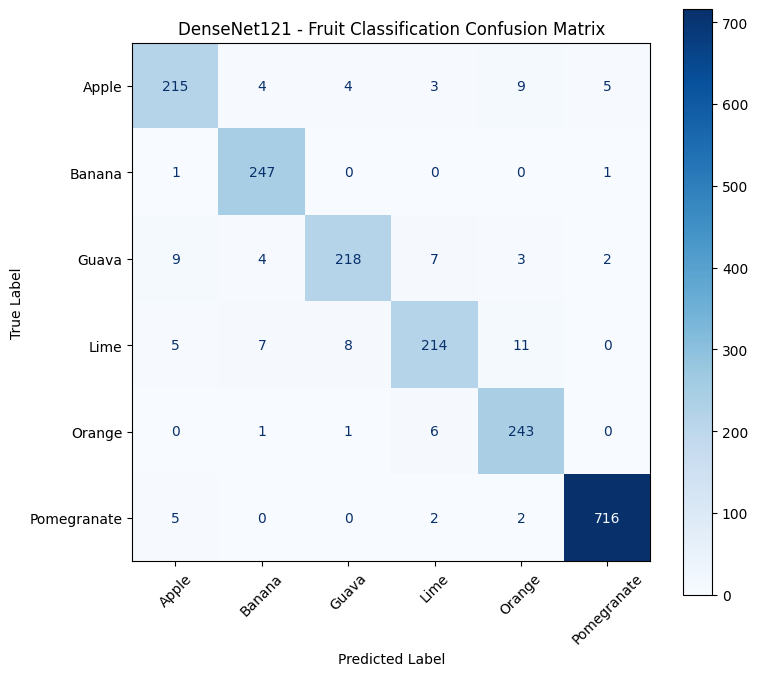


DENSENET121 - FRUIT QUALITY CLASSIFICATION TESTING

QUALITY CLASSIFICATION RESULTS
Accuracy           : 94.21%
Weighted Precision : 94.11%
Weighted Recall    : 94.21%
Weighted F1-score  : 94.10%
Average Inference Time : 0.005710 seconds/sample

DENSENET121 - FRUIT QUALITY CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Good     0.9548    0.9597    0.9572      1166
         Bad     0.9325    0.9558    0.9440       679
       Mixed     0.8471    0.6667    0.7461       108

    accuracy                         0.9421      1953
   macro avg     0.9114    0.8607    0.8824      1953
weighted avg     0.9411    0.9421    0.9410      1953

Quality Confusion Matrix:
[[1119   42    5]
 [  22  649    8]
 [  31    5   72]]


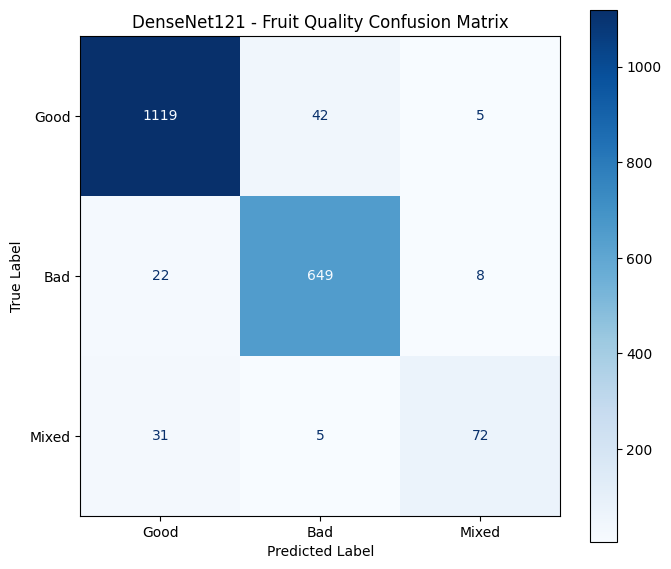


FINAL DENSENET121 TEST RESULTS
Number of Test Samples : 1953

FRUIT CLASSIFICATION
Accuracy  : 94.88%
Precision : 94.90%
Recall    : 94.88%
F1-score  : 94.85%

FRUIT QUALITY CLASSIFICATION
Accuracy  : 94.21%
Precision : 94.11%
Recall    : 94.21%
F1-score  : 94.10%

Testing completed successfully.


In [24]:
# ============================================================
# DENSENET121
# FRUIT + QUALITY TESTING
# CLASSIFICATION REPORT + CONFUSION MATRICES
# ============================================================

import os
import time
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision.models import densenet121

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. CLASS NAMES
# ============================================================

fruit_classes = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

quality_classes = [
    "Good",
    "Bad",
    "Mixed"
]


# ============================================================
# 2. CREATE DENSENET121 FRUIT MODEL
# ============================================================

fruit_model = densenet121(
    weights=None
)

num_features = fruit_model.classifier.in_features

fruit_model.classifier = nn.Linear(
    num_features,
    6
)

fruit_model = fruit_model.to(device)


# ============================================================
# 3. LOAD FRUIT MODEL
# ============================================================

fruit_model_path = (
    "/content/drive/MyDrive/Fruit_Classification_project/"
    "DenseNet121_Fruit_Checkpoints/best_model.pth"
)

checkpoint = torch.load(
    fruit_model_path,
    map_location=device
)

# Handle both possible checkpoint formats
if "model_state_dict" in checkpoint:
    fruit_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    fruit_model.load_state_dict(checkpoint)

fruit_model.eval()

print("DenseNet121 Fruit Model Loaded Successfully")


# ============================================================
# 4. CREATE DENSENET121 QUALITY MODEL
# ============================================================

quality_model = densenet121(
    weights=None
)

num_features = quality_model.classifier.in_features

quality_model.classifier = nn.Linear(
    num_features,
    3
)

quality_model = quality_model.to(device)


# ============================================================
# 5. LOAD QUALITY MODEL
# ============================================================

quality_model_path = (
    "/content/drive/MyDrive/Fruit_Classification_project/"
    "DenseNet121_Quality_Checkpoints/best_model.pth"
)

checkpoint = torch.load(
    quality_model_path,
    map_location=device
)

if "model_state_dict" in checkpoint:
    quality_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    quality_model.load_state_dict(checkpoint)

quality_model.eval()

print("DenseNet121 Quality Model Loaded Successfully")

print("\nBoth DenseNet121 models are ready for testing.")


# ============================================================
# 6. FRUIT CLASSIFICATION TESTING
# ============================================================

fruit_true = []
fruit_pred = []

fruit_times = []

print("\n" + "=" * 70)
print("DENSENET121 - FRUIT CLASSIFICATION TESTING")
print("=" * 70)


with torch.no_grad():

    for images, labels in f_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        start_time = time.time()

        outputs = fruit_model(images)

        end_time = time.time()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        fruit_times.append(
            (end_time - start_time)
            / images.size(0)
        )

        fruit_true.extend(
            labels.cpu().numpy()
        )

        fruit_pred.extend(
            predictions.cpu().numpy()
        )


# ============================================================
# 7. FRUIT METRICS
# ============================================================

fruit_accuracy = accuracy_score(
    fruit_true,
    fruit_pred
)

fruit_precision = precision_score(
    fruit_true,
    fruit_pred,
    average="weighted",
    zero_division=0
)

fruit_recall = recall_score(
    fruit_true,
    fruit_pred,
    average="weighted",
    zero_division=0
)

fruit_f1 = f1_score(
    fruit_true,
    fruit_pred,
    average="weighted",
    zero_division=0
)


print("\nFRUIT CLASSIFICATION RESULTS")

print(
    f"Accuracy           : "
    f"{fruit_accuracy * 100:.2f}%"
)

print(
    f"Weighted Precision : "
    f"{fruit_precision * 100:.2f}%"
)

print(
    f"Weighted Recall    : "
    f"{fruit_recall * 100:.2f}%"
)

print(
    f"Weighted F1-score  : "
    f"{fruit_f1 * 100:.2f}%"
)

print(
    f"Average Inference Time : "
    f"{sum(fruit_times) / len(fruit_times):.6f} "
    f"seconds/sample"
)


# ============================================================
# 8. FRUIT CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("DENSENET121 - FRUIT CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        fruit_true,
        fruit_pred,
        target_names=fruit_classes,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 9. FRUIT CONFUSION MATRIX
# ============================================================

fruit_cm = confusion_matrix(
    fruit_true,
    fruit_pred
)

print("Fruit Confusion Matrix:")
print(fruit_cm)


fig, ax = plt.subplots(
    figsize=(8, 7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=fruit_cm,
    display_labels=fruit_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

ax.set_title(
    "DenseNet121 - Fruit Classification Confusion Matrix"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()


# ============================================================
# 10. QUALITY CLASSIFICATION TESTING
# ============================================================

quality_true = []
quality_pred = []

quality_times = []

print("\n" + "=" * 70)
print("DENSENET121 - FRUIT QUALITY CLASSIFICATION TESTING")
print("=" * 70)


with torch.no_grad():

    for images, labels in q_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        start_time = time.time()

        outputs = quality_model(images)

        end_time = time.time()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        quality_times.append(
            (end_time - start_time)
            / images.size(0)
        )

        quality_true.extend(
            labels.cpu().numpy()
        )

        quality_pred.extend(
            predictions.cpu().numpy()
        )


# ============================================================
# 11. QUALITY METRICS
# ============================================================

quality_accuracy = accuracy_score(
    quality_true,
    quality_pred
)

quality_precision = precision_score(
    quality_true,
    quality_pred,
    average="weighted",
    zero_division=0
)

quality_recall = recall_score(
    quality_true,
    quality_pred,
    average="weighted",
    zero_division=0
)

quality_f1 = f1_score(
    quality_true,
    quality_pred,
    average="weighted",
    zero_division=0
)


print("\nQUALITY CLASSIFICATION RESULTS")

print(
    f"Accuracy           : "
    f"{quality_accuracy * 100:.2f}%"
)

print(
    f"Weighted Precision : "
    f"{quality_precision * 100:.2f}%"
)

print(
    f"Weighted Recall    : "
    f"{quality_recall * 100:.2f}%"
)

print(
    f"Weighted F1-score  : "
    f"{quality_f1 * 100:.2f}%"
)

print(
    f"Average Inference Time : "
    f"{sum(quality_times) / len(quality_times):.6f} "
    f"seconds/sample"
)


# ============================================================
# 12. QUALITY CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("DENSENET121 - FRUIT QUALITY CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        quality_true,
        quality_pred,
        target_names=quality_classes,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 13. QUALITY CONFUSION MATRIX
# ============================================================

quality_cm = confusion_matrix(
    quality_true,
    quality_pred
)

print("Quality Confusion Matrix:")
print(quality_cm)


fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=quality_cm,
    display_labels=quality_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title(
    "DenseNet121 - Fruit Quality Confusion Matrix"
)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL DENSENET121 TEST RESULTS")
print("=" * 70)

print(
    f"Number of Test Samples : {len(fruit_true)}"
)

print("\nFRUIT CLASSIFICATION")
print(
    f"Accuracy  : {fruit_accuracy * 100:.2f}%"
)
print(
    f"Precision : {fruit_precision * 100:.2f}%"
)
print(
    f"Recall    : {fruit_recall * 100:.2f}%"
)
print(
    f"F1-score  : {fruit_f1 * 100:.2f}%"
)

print("\nFRUIT QUALITY CLASSIFICATION")
print(
    f"Accuracy  : {quality_accuracy * 100:.2f}%"
)
print(
    f"Precision : {quality_precision * 100:.2f}%"
)
print(
    f"Recall    : {quality_recall * 100:.2f}%"
)
print(
    f"F1-score  : {quality_f1 * 100:.2f}%"
)

print("\nTesting completed successfully.")

In [25]:
class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden_channels = max(channels // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(
                channels,
                hidden_channels,
                kernel_size=1,
                bias=False
            ),
            nn.ReLU(),
            nn.Conv2d(
                hidden_channels,
                channels,
                kernel_size=1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_attention = self.mlp(self.avg_pool(x))
        max_attention = self.mlp(self.max_pool(x))

        attention = avg_attention + max_attention

        return x * self.sigmoid(attention)


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        padding = kernel_size // 2

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=kernel_size,
            padding=padding,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_attention = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_attention, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        attention = torch.cat(
            [avg_attention, max_attention],
            dim=1
        )

        attention = self.conv(attention)

        return x * self.sigmoid(attention)


class CBAM(nn.Module):

    def __init__(
        self,
        channels,
        reduction=16,
        kernel_size=7
    ):
        super().__init__()

        self.channel_attention = ChannelAttention(
            channels,
            reduction
        )

        self.spatial_attention = SpatialAttention(
            kernel_size
        )

    def forward(self, x):

        x = self.channel_attention(x)
        x = self.spatial_attention(x)

        return x


print("CBAM created successfully.")

CBAM created successfully.


In [26]:
class DenseNet121_CBAM_MTL(nn.Module):

    def __init__(
        self,
        num_fruit_classes=6,
        num_quality_classes=3
    ):
        super().__init__()

        # DenseNet121 ImageNet backbone
        self.backbone = densenet121(
            weights="IMAGENET1K_V1"
        )

        feature_channels = self.backbone.classifier.in_features

        # Remove original classifier
        self.backbone.classifier = nn.Identity()

        # CBAM attention
        self.cbam = CBAM(
            channels=feature_channels
        )

        # Global average pooling
        self.avgpool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        # Fruit classification head
        self.fruit_head = nn.Linear(
            feature_channels,
            num_fruit_classes
        )

        # Quality classification head
        self.quality_head = nn.Linear(
            feature_channels,
            num_quality_classes
        )

    def forward(self, x):

        # DenseNet feature extraction
        x = self.backbone.features(x)

        x = torch.relu(x)

        # CBAM
        x = self.cbam(x)

        # Global average pooling
        x = self.avgpool(x)

        # Flatten
        x = torch.flatten(
            x,
            start_dim=1
        )

        # Two MTL outputs
        fruit_output = self.fruit_head(x)

        quality_output = self.quality_head(x)

        return fruit_output, quality_output


cbam_mtl_model = DenseNet121_CBAM_MTL(
    num_fruit_classes=6,
    num_quality_classes=3
)

cbam_mtl_model = cbam_mtl_model.to(device)

print("=" * 70)
print("DenseNet121 + CBAM + Multi-Task Learning")
print("=" * 70)
print("Backbone        : DenseNet121")
print("Attention       : CBAM")
print("Learning Type   : Multi-Task Learning")
print("Fruit Classes   : 6")
print("Quality Classes : 3")
print("Model created successfully.")

DenseNet121 + CBAM + Multi-Task Learning
Backbone        : DenseNet121
Attention       : CBAM
Learning Type   : Multi-Task Learning
Fruit Classes   : 6
Quality Classes : 3
Model created successfully.


In [27]:
train_df = pd.read_csv(
    "/content/drive/MyDrive/Fruit_Classification_project/splits/train.csv"
)

val_df = pd.read_csv(
    "/content/drive/MyDrive/Fruit_Classification_project/splits/val.csv"
)

test_df = pd.read_csv(
    "/content/drive/MyDrive/Fruit_Classification_project/splits/test.csv"
)

print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nColumns:")
print(train_df.columns.tolist())

Train samples: 13668
Validation samples: 3906
Test samples: 1953

Columns:
['image_path', 'fruit', 'quality', 'combined_label']


In [28]:
def fix_image_path(path):

    path = str(path)

    path = path.replace(
        "/content/drive/MyDrive/Fruit_Classification_Project/",
        "/content/drive/MyDrive/Fruit_Classification_project/"
    )

    return path


train_df["image_path"] = train_df["image_path"].apply(
    fix_image_path
)

val_df["image_path"] = val_df["image_path"].apply(
    fix_image_path
)

test_df["image_path"] = test_df["image_path"].apply(
    fix_image_path
)


train_exists = train_df["image_path"].apply(
    os.path.exists
).sum()

val_exists = val_df["image_path"].apply(
    os.path.exists
).sum()

test_exists = test_df["image_path"].apply(
    os.path.exists
).sum()


print("Train images found:",
      train_exists, "/", len(train_df))

print("Validation images found:",
      val_exists, "/", len(val_df))

print("Test images found:",
      test_exists, "/", len(test_df))

Train images found: 13668 / 13668
Validation images found: 3906 / 3906
Test images found: 1953 / 1953


In [29]:
class FruitQualityMTLDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

        self.fruit_to_idx = {
            "Apple": 0,
            "Banana": 1,
            "Guava": 2,
            "Lime": 3,
            "Orange": 4,
            "Pomegranate": 5
        }

        self.quality_to_idx = {
            "Good": 0,
            "Bad": 1,
            "Mixed": 2
        }

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = row["image_path"]

        image = Image.open(
            image_path
        ).convert("RGB")

        fruit_label = self.fruit_to_idx[
            row["fruit"]
        ]

        quality_label = self.quality_to_idx[
            row["quality"]
        ]

        if self.transform is not None:
            image = self.transform(image)

        return (
            image,
            torch.tensor(
                fruit_label,
                dtype=torch.long
            ),
            torch.tensor(
                quality_label,
                dtype=torch.long
            )
        )


print("MTL Dataset created successfully.")

MTL Dataset created successfully.


In [30]:
batch_size = 8

mtl_train_dataset = FruitQualityMTLDataset(
    train_df,
    transform=transform
)

mtl_val_dataset = FruitQualityMTLDataset(
    val_df,
    transform=preprocess
)

mtl_test_dataset = FruitQualityMTLDataset(
    test_df,
    transform=preprocess
)


mtl_train_loader = DataLoader(
    mtl_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

mtl_val_loader = DataLoader(
    mtl_val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

mtl_test_loader = DataLoader(
    mtl_test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


print("MTL DataLoaders created successfully.")
print("Batch size:", batch_size)
print("Train batches:", len(mtl_train_loader))
print("Validation batches:", len(mtl_val_loader))
print("Test batches:", len(mtl_test_loader))

MTL DataLoaders created successfully.
Batch size: 8
Train batches: 1709
Validation batches: 489
Test batches: 245


In [31]:
from PIL import Image

batch = next(iter(mtl_train_loader))

images, fruit_labels, quality_labels = batch

print("Number of outputs:", len(batch))
print("Images shape:", images.shape)
print("Fruit labels shape:", fruit_labels.shape)
print("Quality labels shape:", quality_labels.shape)

print("\nFirst fruit labels:")
print(fruit_labels[:8])

print("\nFirst quality labels:")
print(quality_labels[:8])

print("\nMTL DataLoader verification successful.")

Number of outputs: 3
Images shape: torch.Size([8, 3, 224, 224])
Fruit labels shape: torch.Size([8])
Quality labels shape: torch.Size([8])

First fruit labels:
tensor([4, 3, 3, 1, 3, 4, 0, 0])

First quality labels:
tensor([1, 1, 0, 0, 2, 1, 0, 1])

MTL DataLoader verification successful.


In [32]:
fruit_criterion = nn.CrossEntropyLoss()

quality_criterion = nn.CrossEntropyLoss()

lambda_fruit = 1.0
lambda_quality = 1.0

learning_rate = 0.01

optimizer = torch.optim.AdamW(
    cbam_mtl_model.parameters(),
    lr=learning_rate,
    weight_decay=1e-2
)


print("Multi-Task Learning setup created successfully.")
print("Fruit Loss     : CrossEntropyLoss")
print("Quality Loss   : CrossEntropyLoss")
print("Lambda Fruit   :", lambda_fruit)
print("Lambda Quality :", lambda_quality)
print("Learning Rate  :", learning_rate)
print("Weight Decay   :", 1e-2)
print("Optimizer      : AdamW")

Multi-Task Learning setup created successfully.
Fruit Loss     : CrossEntropyLoss
Quality Loss   : CrossEntropyLoss
Lambda Fruit   : 1.0
Lambda Quality : 1.0
Learning Rate  : 0.01
Weight Decay   : 0.01
Optimizer      : AdamW


In [33]:
def train_one_epoch_mtl(
    model,
    train_loader,
    optimizer,
    fruit_criterion,
    quality_criterion,
    lambda_fruit=1.0,
    lambda_quality=1.0,
    device="cuda"
):

    model.train()

    total_loss = 0.0
    total_fruit_loss = 0.0
    total_quality_loss = 0.0

    fruit_correct = 0
    quality_correct = 0

    total_samples = 0

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        unit="batch"
    )

    for images, fruit_labels, quality_labels in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        fruit_labels = fruit_labels.to(
            device,
            non_blocking=True
        )

        quality_labels = quality_labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        fruit_outputs, quality_outputs = model(
            images
        )

        fruit_loss = fruit_criterion(
            fruit_outputs,
            fruit_labels
        )

        quality_loss = quality_criterion(
            quality_outputs,
            quality_labels
        )

        loss = (
            lambda_fruit * fruit_loss
            +
            lambda_quality * quality_loss
        )

        loss.backward()

        optimizer.step()

        current_batch_size = images.size(0)

        total_loss += (
            loss.item() * current_batch_size
        )

        total_fruit_loss += (
            fruit_loss.item() * current_batch_size
        )

        total_quality_loss += (
            quality_loss.item() * current_batch_size
        )

        fruit_predictions = fruit_outputs.argmax(
            dim=1
        )

        quality_predictions = quality_outputs.argmax(
            dim=1
        )

        fruit_correct += (
            fruit_predictions == fruit_labels
        ).sum().item()

        quality_correct += (
            quality_predictions == quality_labels
        ).sum().item()

        total_samples += current_batch_size

        progress_bar.set_postfix({
            "Loss": f"{loss.item():.4f}",
            "Fruit": f"{100 * fruit_correct / total_samples:.2f}%",
            "Quality": f"{100 * quality_correct / total_samples:.2f}%"
        })

    epoch_loss = total_loss / total_samples

    epoch_fruit_loss = (
        total_fruit_loss / total_samples
    )

    epoch_quality_loss = (
        total_quality_loss / total_samples
    )

    fruit_accuracy = (
        fruit_correct / total_samples
    )

    quality_accuracy = (
        quality_correct / total_samples
    )

    return (
        epoch_loss,
        epoch_fruit_loss,
        epoch_quality_loss,
        fruit_accuracy,
        quality_accuracy
    )


print("MTL training function created successfully.")

MTL training function created successfully.


In [34]:
def validate_mtl(
    model,
    val_loader,
    fruit_criterion,
    quality_criterion,
    lambda_fruit=1.0,
    lambda_quality=1.0,
    device="cuda"
):

    model.eval()

    total_loss = 0.0
    total_fruit_loss = 0.0
    total_quality_loss = 0.0

    fruit_correct = 0
    quality_correct = 0

    total_samples = 0

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        unit="batch"
    )

    with torch.no_grad():

        for images, fruit_labels, quality_labels in progress_bar:

            images = images.to(
                device,
                non_blocking=True
            )

            fruit_labels = fruit_labels.to(
                device,
                non_blocking=True
            )

            quality_labels = quality_labels.to(
                device,
                non_blocking=True
            )

            fruit_outputs, quality_outputs = model(
                images
            )

            fruit_loss = fruit_criterion(
                fruit_outputs,
                fruit_labels
            )

            quality_loss = quality_criterion(
                quality_outputs,
                quality_labels
            )

            loss = (
                lambda_fruit * fruit_loss
                +
                lambda_quality * quality_loss
            )

            current_batch_size = images.size(0)

            total_loss += (
                loss.item() * current_batch_size
            )

            total_fruit_loss += (
                fruit_loss.item() * current_batch_size
            )

            total_quality_loss += (
                quality_loss.item() * current_batch_size
            )

            fruit_predictions = fruit_outputs.argmax(
                dim=1
            )

            quality_predictions = quality_outputs.argmax(
                dim=1
            )

            fruit_correct += (
                fruit_predictions == fruit_labels
            ).sum().item()

            quality_correct += (
                quality_predictions == quality_labels
            ).sum().item()

            total_samples += current_batch_size

            progress_bar.set_postfix({
                "Loss": f"{loss.item():.4f}",
                "Fruit": f"{100 * fruit_correct / total_samples:.2f}%",
                "Quality": f"{100 * quality_correct / total_samples:.2f}%"
            })

    epoch_loss = total_loss / total_samples

    epoch_fruit_loss = (
        total_fruit_loss / total_samples
    )

    epoch_quality_loss = (
        total_quality_loss / total_samples
    )

    fruit_accuracy = (
        fruit_correct / total_samples
    )

    quality_accuracy = (
        quality_correct / total_samples
    )

    return (
        epoch_loss,
        epoch_fruit_loss,
        epoch_quality_loss,
        fruit_accuracy,
        quality_accuracy
    )


print("MTL validation function created successfully.")

MTL validation function created successfully.


In [35]:
mtl_checkpoint_dir = (
    "/content/drive/MyDrive/"
    "Fruit_Classification_project/"
    "fruitcheckpoints_DenseNet121_CBAM_MTL"
)

os.makedirs(
    mtl_checkpoint_dir,
    exist_ok=True
)

latest_checkpoint_path = os.path.join(
    mtl_checkpoint_dir,
    "latest_checkpoint.pth"
)

best_checkpoint_path = os.path.join(
    mtl_checkpoint_dir,
    "best_model.pth"
)

num_epochs = 30

start_epoch = 0

best_val_accuracy = 0.0


if os.path.exists(latest_checkpoint_path):

    print("Checkpoint found.")
    print(
        "Loading:",
        latest_checkpoint_path
    )

    checkpoint = torch.load(
        latest_checkpoint_path,
        map_location=device
    )

    cbam_mtl_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = (
        checkpoint["epoch"] + 1
    )

    best_val_accuracy = checkpoint.get(
        "best_val_accuracy",
        0.0
    )

    print("Checkpoint loaded successfully.")
    print(
        "Next epoch:",
        start_epoch + 1
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_accuracy * 100:.2f}%"
    )

else:

    print("No previous checkpoint found.")
    print("Training will start from epoch 1.")


print()
print(
    "Checkpoint directory:",
    mtl_checkpoint_dir
)

print(
    "Total epochs:",
    num_epochs
)

Checkpoint found.
Loading: /content/drive/MyDrive/Fruit_Classification_project/fruitcheckpoints_DenseNet121_CBAM_MTL/latest_checkpoint.pth
Checkpoint loaded successfully.
Next epoch: 31
Best validation accuracy: 94.30%

Checkpoint directory: /content/drive/MyDrive/Fruit_Classification_project/fruitcheckpoints_DenseNet121_CBAM_MTL
Total epochs: 30


In [36]:
for epoch in range(
    start_epoch,
    num_epochs
):

    print("\n" + "=" * 70)

    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print("=" * 70)

    # =============================
    # Training
    # =============================

    (
        train_loss,
        train_fruit_loss,
        train_quality_loss,
        train_fruit_acc,
        train_quality_acc
    ) = train_one_epoch_mtl(
        model=cbam_mtl_model,

        # IMPORTANT:
        # Use MTL loader
        train_loader=mtl_train_loader,

        optimizer=optimizer,

        fruit_criterion=fruit_criterion,

        quality_criterion=quality_criterion,

        lambda_fruit=lambda_fruit,

        lambda_quality=lambda_quality,

        device=device
    )


    # =============================
    # Validation
    # =============================

    (
        val_loss,
        val_fruit_loss,
        val_quality_loss,
        val_fruit_acc,
        val_quality_acc
    ) = validate_mtl(
        model=cbam_mtl_model,

        # IMPORTANT:
        # Use MTL validation loader
        val_loader=mtl_val_loader,

        fruit_criterion=fruit_criterion,

        quality_criterion=quality_criterion,

        lambda_fruit=lambda_fruit,

        lambda_quality=lambda_quality,

        device=device
    )


    # =============================
    # Combined validation accuracy
    # =============================

    combined_val_accuracy = (
        val_fruit_acc +
        val_quality_acc
    ) / 2


    # =============================
    # Print results
    # =============================

    print("\nEpoch Results")
    print("-" * 70)

    print(
        f"Train Loss        : {train_loss:.4f}"
    )

    print(
        f"Train Fruit Acc   : "
        f"{train_fruit_acc * 100:.2f}%"
    )

    print(
        f"Train Quality Acc : "
        f"{train_quality_acc * 100:.2f}%"
    )

    print(
        f"Val Loss          : {val_loss:.4f}"
    )

    print(
        f"Val Fruit Acc     : "
        f"{val_fruit_acc * 100:.2f}%"
    )

    print(
        f"Val Quality Acc   : "
        f"{val_quality_acc * 100:.2f}%"
    )

    print(
        f"Combined Val Acc  : "
        f"{combined_val_accuracy * 100:.2f}%"
    )


    # =============================
    # Latest checkpoint
    # =============================

    checkpoint = {

        "epoch": epoch,

        "model_state_dict":
            cbam_mtl_model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "train_loss":
            train_loss,

        "val_loss":
            val_loss,

        "train_fruit_accuracy":
            train_fruit_acc,

        "train_quality_accuracy":
            train_quality_acc,

        "val_fruit_accuracy":
            val_fruit_acc,

        "val_quality_accuracy":
            val_quality_acc,

        "combined_val_accuracy":
            combined_val_accuracy,

        "best_val_accuracy":
            best_val_accuracy
    }


    torch.save(
        checkpoint,
        latest_checkpoint_path
    )

    print(
        "Latest checkpoint saved."
    )


    # =============================
    # Best model
    # =============================

    if combined_val_accuracy > best_val_accuracy:

        best_val_accuracy = (
            combined_val_accuracy
        )

        checkpoint[
            "best_val_accuracy"
        ] = best_val_accuracy

        torch.save(
            checkpoint,
            best_checkpoint_path
        )

        print(
            f"Best model saved! "
            f"Combined Val Acc: "
            f"{best_val_accuracy * 100:.2f}%"
        )

    print("=" * 70)

In [39]:
# ============================================================
# FAST TESTING — DENSENET121 + CBAM + MTL
# ============================================================

import torch
from sklearn.metrics import accuracy_score, classification_report

# Load checkpoint directly using the correct checkpoint variable
checkpoint = torch.load(
    best_checkpoint_path,
    map_location=device
)

cbam_mtl_model.load_state_dict(
    checkpoint["model_state_dict"]
)

cbam_mtl_model.to(device)
cbam_mtl_model.eval()

print("Checkpoint loaded successfully.")
print("Starting test...")

fruit_true = []
fruit_pred = []

quality_true = []
quality_pred = []

with torch.no_grad():

    for images, fruit_labels, quality_labels in mtl_test_loader:

        images = images.to(device)

        fruit_outputs, quality_outputs = cbam_mtl_model(images)

        fruit_predictions = torch.argmax(
            fruit_outputs,
            dim=1
        )

        quality_predictions = torch.argmax(
            quality_outputs,
            dim=1
        )

        fruit_true.extend(
            fruit_labels.numpy()
        )

        fruit_pred.extend(
            fruit_predictions.cpu().numpy()
        )

        quality_true.extend(
            quality_labels.numpy()
        )

        quality_pred.extend(
            quality_predictions.cpu().numpy()
        )

# Accuracy
fruit_accuracy = accuracy_score(
    fruit_true,
    fruit_pred
)

quality_accuracy = accuracy_score(
    quality_true,
    quality_pred
)

combined_accuracy = (
    fruit_accuracy + quality_accuracy
) / 2

print("\n" + "=" * 60)
print("TEST RESULTS")
print("=" * 60)

print(
    f"Fruit Accuracy    : {fruit_accuracy * 100:.2f}%"
)

print(
    f"Quality Accuracy  : {quality_accuracy * 100:.2f}%"
)

print(
    f"Combined Accuracy : {combined_accuracy * 100:.2f}%"
)

print("\nFruit Classification Report:")
print(
    classification_report(
        fruit_true,
        fruit_pred,
        target_names=[
            "Apple",
            "Banana",
            "Guava",
            "Lime",
            "Orange",
            "Pomegranate"
        ],
        digits=4
    )
)

print("\nQuality Classification Report:")
print(
    classification_report(
        quality_true,
        quality_pred,
        target_names=[
            "Good",
            "Bad",
            "Mixed"
        ],
        digits=4
    )
)

Checkpoint loaded successfully.
Starting test...

TEST RESULTS
Fruit Accuracy    : 93.04%
Quality Accuracy  : 94.57%
Combined Accuracy : 93.80%

Fruit Classification Report:
              precision    recall  f1-score   support

       Apple     0.8727    0.8000    0.8348       240
      Banana     0.9108    0.9839    0.9459       249
       Guava     0.8485    0.9218    0.8836       243
        Lime     0.9402    0.8980    0.9186       245
      Orange     0.9627    0.9243    0.9431       251
 Pomegranate     0.9710    0.9710    0.9710       725

    accuracy                         0.9304      1953
   macro avg     0.9176    0.9165    0.9162      1953
weighted avg     0.9311    0.9304    0.9300      1953


Quality Classification Report:
              precision    recall  f1-score   support

        Good     0.9461    0.9786    0.9621      1166
         Bad     0.9735    0.9205    0.9463       679
       Mixed     0.7714    0.7500    0.7606       108

    accuracy                     

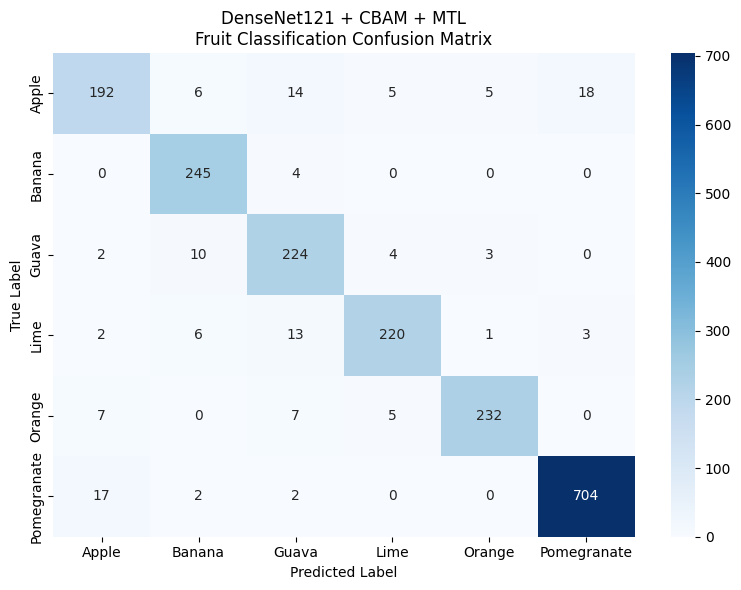

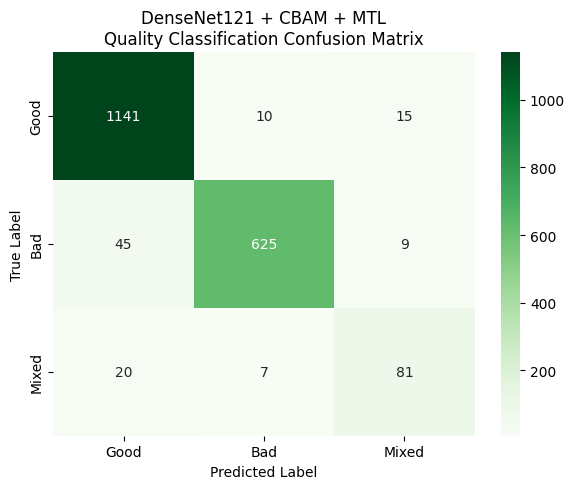

In [41]:
# ============================================================
# CONFUSION MATRICES
# DenseNet121 + CBAM + Multi-Task Learning
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. CREATE CONFUSION MATRICES
# ------------------------------------------------------------

fruit_cm = confusion_matrix(
    fruit_true,
    fruit_pred
)

quality_cm = confusion_matrix(
    quality_true,
    quality_pred
)


# ------------------------------------------------------------
# 2. FRUIT CONFUSION MATRIX
# ------------------------------------------------------------

fruit_classes = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    fruit_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=fruit_classes,
    yticklabels=fruit_classes
)

plt.title(
    "DenseNet121 + CBAM + MTL\nFruit Classification Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 3. QUALITY CONFUSION MATRIX
# ------------------------------------------------------------

quality_classes = [
    "Good",
    "Bad",
    "Mixed"
]

plt.figure(figsize=(6, 5))

sns.heatmap(
    quality_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=quality_classes,
    yticklabels=quality_classes
)

plt.title(
    "DenseNet121 + CBAM + MTL\nQuality Classification Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.show()

In [42]:
# ============================================================
# CBAM ATTENTION VISUALIZATION
# DenseNet121 + CBAM + MTL
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from torchvision.transforms.functional import to_pil_image

# ------------------------------------------------------------
# 1. GET ONE TEST IMAGE
# ------------------------------------------------------------

image, fruit_label, quality_label = mtl_test_dataset[0]

# Add batch dimension
input_image = image.unsqueeze(0).to(device)


# ------------------------------------------------------------
# 2. STORE CBAM ATTENTION
# ------------------------------------------------------------

attention_map = {}


def save_attention(module, input, output):
    attention_map["cbam"] = output.detach().cpu()


# Register hook on CBAM
hook = mtl_model.cbam.register_forward_hook(
    save_attention
)


# ------------------------------------------------------------
# 3. MODEL PREDICTION
# ------------------------------------------------------------

mtl_model.eval()

with torch.no_grad():

    fruit_output, quality_output = mtl_model(
        input_image
    )


# Remove hook
hook.remove()


# ------------------------------------------------------------
# 4. GET ATTENTION FEATURES
# ------------------------------------------------------------

attention_features = attention_map["cbam"]

print(
    "Attention feature shape:",
    attention_features.shape
)


# ------------------------------------------------------------
# 5. CREATE ATTENTION MAP
# ------------------------------------------------------------

# Average across feature channels
attention = torch.mean(
    attention_features,
    dim=1
).squeeze(0)

# Convert to numpy
attention = attention.numpy()

# Normalize between 0 and 1
attention = (
    attention - attention.min()
) / (
    attention.max() - attention.min() + 1e-8
)


# ------------------------------------------------------------
# 6. ORIGINAL IMAGE
# ------------------------------------------------------------

original_image = image.cpu()

# Undo ImageNet normalization
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

original_image = (
    original_image * std + mean
)

original_image = torch.clamp(
    original_image,
    0,
    1
)


# ------------------------------------------------------------
# 7. RESIZE ATTENTION MAP
# ------------------------------------------------------------

attention_pil = Image.fromarray(
    np.uint8(attention * 255)
)

attention_pil = attention_pil.resize(
    (224, 224),
    Image.BILINEAR
)

attention_resized = np.array(
    attention_pil
) / 255.0


# ------------------------------------------------------------
# 8. GET PREDICTIONS
# ------------------------------------------------------------

fruit_prediction = torch.argmax(
    fruit_output,
    dim=1
).item()

quality_prediction = torch.argmax(
    quality_output,
    dim=1
).item()


fruit_names = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

quality_names = [
    "Good",
    "Bad",
    "Mixed"
]


print(
    "Predicted Fruit:",
    fruit_names[fruit_prediction]
)

print(
    "Predicted Quality:",
    quality_names[quality_prediction]
)


# ------------------------------------------------------------
# 9. VISUALIZE
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))


# Original image
plt.subplot(1, 3, 1)

plt.imshow(
    original_image.permute(1, 2, 0)
)

plt.title("Original Image")

plt.axis("off")


# Attention map
plt.subplot(1, 3, 2)

plt.imshow(
    attention_resized,
    cmap="jet"
)

plt.title("CBAM Attention Map")

plt.axis("off")


# Overlay
plt.subplot(1, 3, 3)

plt.imshow(
    original_image.permute(1, 2, 0)
)

plt.imshow(
    attention_resized,
    cmap="jet",
    alpha=0.45
)

plt.title(
    "CBAM Attention Overlay"
)

plt.axis("off")


plt.tight_layout()

plt.show()

NameError: name 'mtl_model' is not defined

Selected Random Test Image Index: 1730
Attention feature shape: torch.Size([1, 1024, 7, 7])
Ground Truth - Fruit: Guava, Quality: Good
Predicted    - Fruit: Guava, Quality: Good


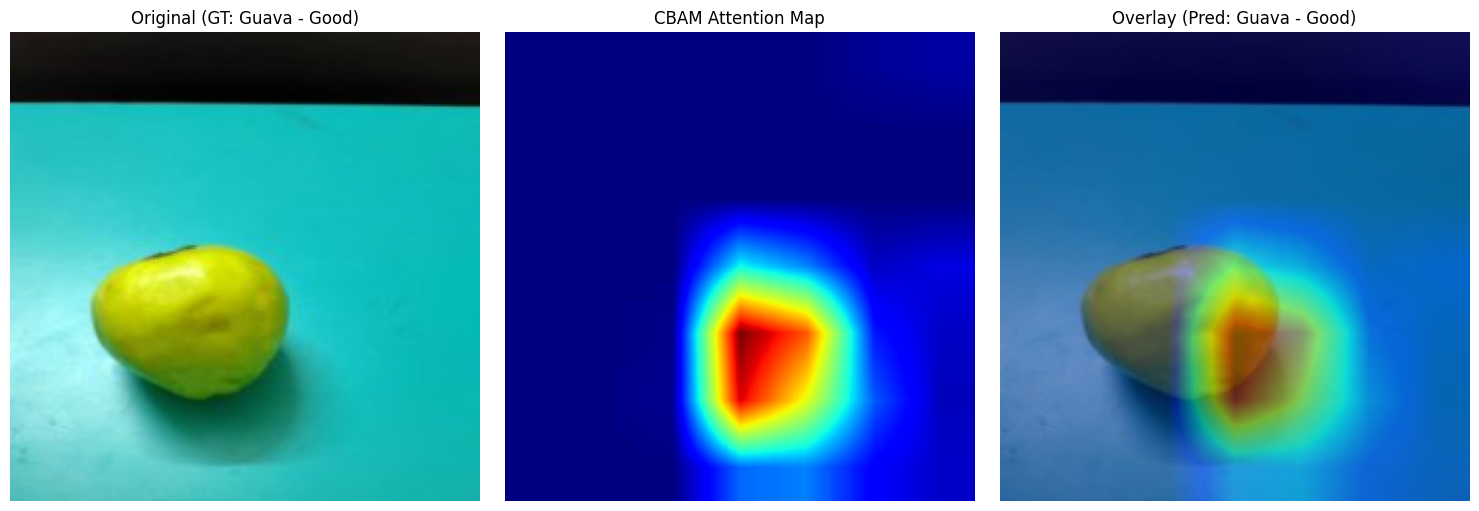

In [44]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
from PIL import Image

# 1. GET A RANDOM TEST IMAGE
random_idx = random.randint(0, len(mtl_test_dataset) - 1)
image, fruit_label, quality_label = mtl_test_dataset[random_idx]
print(f"Selected Random Test Image Index: {random_idx}")

# Add batch dimension
input_image = image.unsqueeze(0).to(device)

# 2. STORE CBAM ATTENTION
attention_map = {}

def save_attention(module, input, output):
    attention_map["cbam"] = output.detach().cpu()

# Register hook on CBAM (using the correct model name cbam_mtl_model)
hook = cbam_mtl_model.cbam.register_forward_hook(save_attention)

# 3. MODEL PREDICTION
cbam_mtl_model.eval()
with torch.no_grad():
    fruit_output, quality_output = cbam_mtl_model(input_image)

# Remove hook
hook.remove()

# 4. GET ATTENTION FEATURES
attention_features = attention_map["cbam"]
print("Attention feature shape:", attention_features.shape)

# 5. CREATE ATTENTION MAP
# Average across feature channels
attention = torch.mean(attention_features, dim=1).squeeze(0)
attention = attention.numpy()

# Normalize between 0 and 1
attention = (attention - attention.min()) / (attention.max() - attention.min() + 1e-8)

# 6. ORIGINAL IMAGE
original_image = image.cpu()

# Undo ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
original_image = (original_image * std + mean)
original_image = torch.clamp(original_image, 0, 1)

# 7. RESIZE ATTENTION MAP
attention_pil = Image.fromarray(np.uint8(attention * 255))
attention_pil = attention_pil.resize((224, 224), Image.BILINEAR)
attention_resized = np.array(attention_pil) / 255.0

# 8. GET PREDICTIONS AND GROUND TRUTH
fruit_prediction = torch.argmax(fruit_output, dim=1).item()
quality_prediction = torch.argmax(quality_output, dim=1).item()

fruit_names = ["Apple", "Banana", "Guava", "Lime", "Orange", "Pomegranate"]
quality_names = ["Good", "Bad", "Mixed"]

print(f"Ground Truth - Fruit: {fruit_names[fruit_label]}, Quality: {quality_names[quality_label]}")
print(f"Predicted    - Fruit: {fruit_names[fruit_prediction]}, Quality: {quality_names[quality_prediction]}")

# 9. VISUALIZE
plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(original_image.permute(1, 2, 0))
plt.title(f"Original (GT: {fruit_names[fruit_label]} - {quality_names[quality_label]})")
plt.axis("off")

# Attention map
plt.subplot(1, 3, 2)
plt.imshow(attention_resized, cmap="jet")
plt.title("CBAM Attention Map")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(original_image.permute(1, 2, 0))
plt.imshow(attention_resized, cmap="jet", alpha=0.45)
plt.title(f"Overlay (Pred: {fruit_names[fruit_prediction]} - {quality_names[quality_prediction]})")
plt.axis("off")

plt.tight_layout()
plt.show()

Random Test Image Index: 753

Ground Truth Fruit: Pomegranate
Ground Truth Quality: Bad

Predicted Fruit: Pomegranate
Predicted Quality: Bad


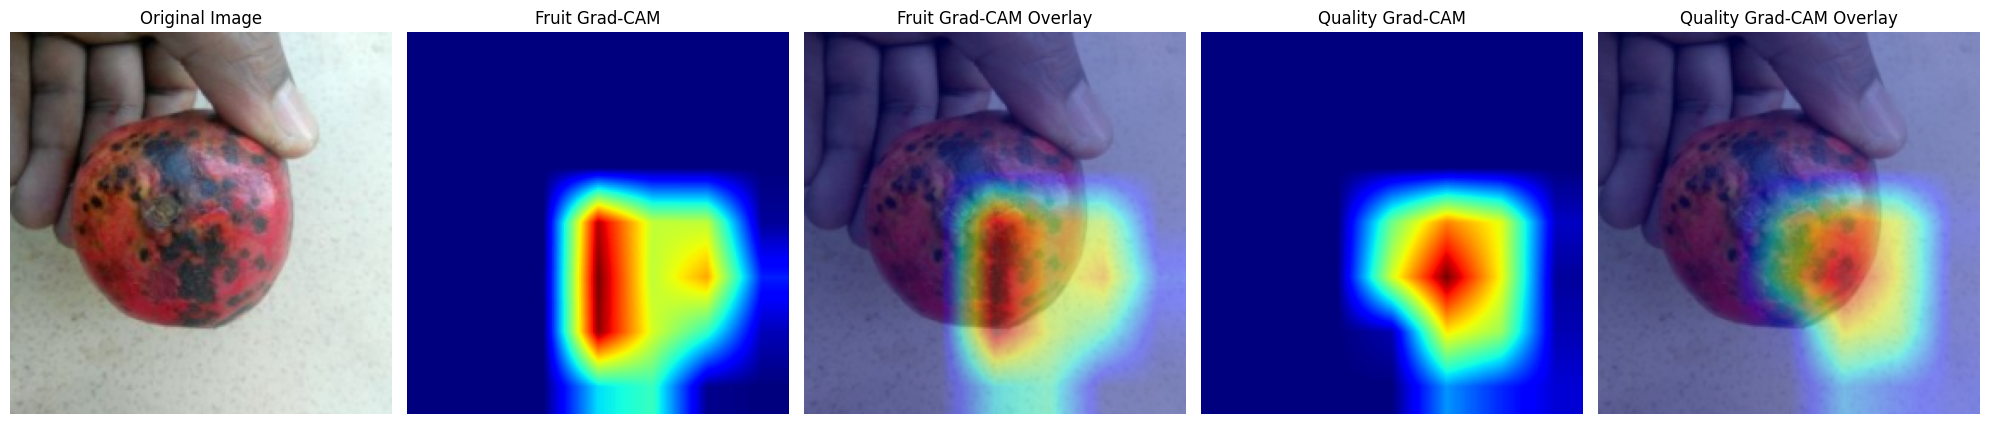

In [57]:
# ============================================================
# CORRECT GRAD-CAM VISUALIZATION
# DenseNet121 + CBAM + MTL
# RANDOM TEST IMAGE
# NO RETRAINING
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random


# ------------------------------------------------------------
# 1. RANDOM TEST IMAGE
# ------------------------------------------------------------

random_index = random.randint(
    0,
    len(mtl_test_dataset) - 1
)

image, fruit_label, quality_label = (
    mtl_test_dataset[random_index]
)

input_image = image.unsqueeze(0).to(device)

print(
    "Random Test Image Index:",
    random_index
)


# ------------------------------------------------------------
# 2. CLASS NAMES
# ------------------------------------------------------------

fruit_names = [
    "Apple",
    "Banana",
    "Guava",
    "Lime",
    "Orange",
    "Pomegranate"
]

quality_names = [
    "Good",
    "Bad",
    "Mixed"
]


# ------------------------------------------------------------
# 3. GRAD-CAM FUNCTION
# ------------------------------------------------------------

def generate_gradcam(target_output, target_class):

    activations = []
    gradients = []


    # --------------------------------------------------------
    # Forward hook
    # --------------------------------------------------------

    def forward_hook(module, inputs, output):

        activations.append(
            output
        )


    # --------------------------------------------------------
    # Backward hook
    # --------------------------------------------------------

    def backward_hook(
        module,
        grad_input,
        grad_output
    ):

        gradients.append(
            grad_output[0]
        )


    # --------------------------------------------------------
    # Register hooks
    # --------------------------------------------------------

    forward_handle = (
        cbam_mtl_model.cbam.register_forward_hook(
            forward_hook
        )
    )

    backward_handle = (
        cbam_mtl_model.cbam.register_full_backward_hook(
            backward_hook
        )
    )


    # --------------------------------------------------------
    # Fresh forward pass
    # --------------------------------------------------------

    cbam_mtl_model.zero_grad()

    fruit_output, quality_output = (
        cbam_mtl_model(input_image)
    )


    # --------------------------------------------------------
    # Select requested output
    # --------------------------------------------------------

    if target_output == "fruit":

        score = fruit_output[
            0,
            target_class
        ]

    else:

        score = quality_output[
            0,
            target_class
        ]


    # --------------------------------------------------------
    # Backward pass
    # --------------------------------------------------------

    score.backward()


    # --------------------------------------------------------
    # Remove hooks
    # --------------------------------------------------------

    forward_handle.remove()
    backward_handle.remove()


    # --------------------------------------------------------
    # Check hooks
    # --------------------------------------------------------

    if len(activations) == 0:

        raise RuntimeError(
            "Grad-CAM activation was not captured."
        )

    if len(gradients) == 0:

        raise RuntimeError(
            "Grad-CAM gradient was not captured."
        )


    # --------------------------------------------------------
    # Get activation and gradient
    # --------------------------------------------------------

    activation = (
        activations[0]
        .detach()
    )

    gradient = (
        gradients[0]
        .detach()
    )


    # --------------------------------------------------------
    # Calculate Grad-CAM weights
    # --------------------------------------------------------

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )


    # --------------------------------------------------------
    # Weighted feature maps
    # --------------------------------------------------------

    cam = (
        weights * activation
    ).sum(
        dim=1,
        keepdim=True
    )


    # --------------------------------------------------------
    # ReLU
    # --------------------------------------------------------

    cam = F.relu(cam)


    # --------------------------------------------------------
    # Resize to image size
    # --------------------------------------------------------

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )


    # --------------------------------------------------------
    # Convert to NumPy
    # --------------------------------------------------------

    cam = (
        cam[0, 0]
        .detach()
        .cpu()
        .numpy()
    )


    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    cam = (
        cam - cam.min()
    ) / (
        cam.max()
        - cam.min()
        + 1e-8
    )


    return cam


# ------------------------------------------------------------
# 4. GET MODEL PREDICTIONS
# ------------------------------------------------------------

cbam_mtl_model.eval()

with torch.no_grad():

    fruit_output, quality_output = (
        cbam_mtl_model(input_image)
    )


fruit_prediction = torch.argmax(
    fruit_output,
    dim=1
).item()

quality_prediction = torch.argmax(
    quality_output,
    dim=1
).item()


# ------------------------------------------------------------
# 5. FRUIT GRAD-CAM
# ------------------------------------------------------------

fruit_cam = generate_gradcam(
    "fruit",
    fruit_prediction
)


# ------------------------------------------------------------
# 6. QUALITY GRAD-CAM
# ------------------------------------------------------------

quality_cam = generate_gradcam(
    "quality",
    quality_prediction
)


# ------------------------------------------------------------
# 7. ORIGINAL RGB IMAGE
# ------------------------------------------------------------

original_image = image.cpu()

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

original_image = (
    original_image * std + mean
)

original_image = torch.clamp(
    original_image,
    0,
    1
)

original_image = (
    original_image
    .permute(1, 2, 0)
    .numpy()
)


# ------------------------------------------------------------
# 8. PRINT RESULTS
# ------------------------------------------------------------

print()

print(
    "Ground Truth Fruit:",
    fruit_names[
        fruit_label.item()
    ]
)

print(
    "Ground Truth Quality:",
    quality_names[
        quality_label.item()
    ]
)

print()

print(
    "Predicted Fruit:",
    fruit_names[
        fruit_prediction
    ]
)

print(
    "Predicted Quality:",
    quality_names[
        quality_prediction
    ]
)


# ------------------------------------------------------------
# 9. VISUALIZATION
# ------------------------------------------------------------

plt.figure(
    figsize=(20, 5)
)


# ------------------------------------------------------------
# Original Image
# ------------------------------------------------------------

plt.subplot(1, 5, 1)

plt.imshow(
    original_image
)

plt.title(
    "Original Image"
)

plt.axis("off")


# ------------------------------------------------------------
# Fruit Grad-CAM
# ------------------------------------------------------------

plt.subplot(1, 5, 2)

plt.imshow(
    fruit_cam,
    cmap="jet"
)

plt.title(
    "Fruit Grad-CAM"
)

plt.axis("off")


# ------------------------------------------------------------
# Fruit Overlay
# ------------------------------------------------------------

plt.subplot(1, 5, 3)

plt.imshow(
    original_image
)

plt.imshow(
    fruit_cam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    "Fruit Grad-CAM Overlay"
)

plt.axis("off")


# ------------------------------------------------------------
# Quality Grad-CAM
# ------------------------------------------------------------

plt.subplot(1, 5, 4)

plt.imshow(
    quality_cam,
    cmap="jet"
)

plt.title(
    "Quality Grad-CAM"
)

plt.axis("off")


# ------------------------------------------------------------
# Quality Overlay
# ------------------------------------------------------------

plt.subplot(1, 5, 5)

plt.imshow(
    original_image
)

plt.imshow(
    quality_cam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    "Quality Grad-CAM Overlay"
)

plt.axis("off")


plt.tight_layout()

plt.show()